In [11]:
import pandas as pd
from pandas import DataFrame  as df

#데이터 불러오기 시간이랑 트윗 텍스트만
Data = pd.read_csv("노년층이 많이 대출한 책(csv).csv")

Data

,검색어,저자,책소개
0,황금종이,조정래,"""말도 마. 돈에 얽힌 일이라면 무슨 일이든지 다 일어나.”\n“큰돈 앞에서는 큰 ..."
1,풍수전쟁,김진명,그의 입에서 여태까지의 목소리가 아니라 남자도 여자도 아닌 마치 다른 세상의 것인 ...
2,아버지의 해방일지,정지아,아버지가 죽었다. 전봇대에 머리를 박고. 평생을 정색하고 살아온 아버지가 전봇대에 ...
3,퓨처 셀프,벤저민 하디,미래의 나와 연결되는 수준이 현재의 삶과 행동의 수준을 결정한다. 연구 결과가 명확...
4,천년의 질문,조정래,장우진은 고석민의 말꼬리에서 문득 물기를 느꼈다. 생활 여건에 무슨 어려움이 생긴 ...
5,너는 다시 외로워질 것이다,공지영,"사랑하는 나의 벗들, 그분께서 나를 산과 바다로 인도하시고 고통의 낚싯바늘에 나를 ..."
6,불편한 편의점,김호연,“근데 이게 마지막 술이에요. 이거 먹고 술 끊는 조건으로 우리 가게 일 좀 봐줘요...
7,작별하지 않는다,한강,생명이 얼마나 약한 것인지 그때 실감했다. 저 살과 장기와 뼈와 목숨 들이 얼마나 ...
8,푸틴을 죽이는 완벽한 방법,김진명,"“음, 내가 푸틴의 침공을 유발했단 건가?”\n“속마음이 어떻든 모호한 태도를 취했..."
9,당신도 느리게 나이 들 수 있습니다,정희원,만성질환은 대개 평생 동안 축적된 노화의 결과다. 한 사람의 가치관과 생활방식이 만...


In [22]:
Data.책소개 = Data.책소개.astype(str)

In [23]:
import pandas as pd
import numpy as np

# 데이터 프레임의 'text' 열의 값들을 str 형식으로 바꾸기
Data['책소개'] = Data['책소개'].astype(str)

# 한글이 아니면 빈 문자열로 바꾸기
Data['책소개'] = Data['책소개'].str.replace('[^ㄱ-ㅎㅏ-ㅣ가-힣]', ' ', regex=True)

# 빈 문자열을 NAN 값으로 바꾸기
Data['책소개'] = Data['책소개'].replace({'': np.nan})
Data['책소개'] = Data['책소개'].replace(r'^\s*$', np.nan, regex=True)

# NAN이 있는 행은 삭제
Data.dropna(subset=['책소개'], how='any', inplace=True)

# 인덱스 차곡차곡
Data = Data.reset_index(drop=True)

# 데이터 프레임에 null 값이 있는지 확인
print(Data.isnull().values.any())


False


In [24]:
from konlpy.tag import Okt
import pandas as pd
import numpy as np

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.extend([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

# 결과를 데이터프레임으로 변환
nouns_df = pd.DataFrame(data_word, columns=['명사'])

# 데이터프레임 출력
print(nouns_df)

        명사
0       간다
1      깨달음
2       술집
3       검지
4       철학
...    ...
2242  도광양회
2243    절망
2244    이익
2245    땅속
2246    성화

[2247 rows x 1 columns]


In [25]:
from konlpy.tag import Okt
import pandas as pd
import numpy as np
import gensim
import re
from gensim.corpora import Dictionary

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.extend([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

# 결과를 데이터프레임으로 변환
nouns_df = pd.DataFrame(data_word, columns=['명사'])

# 데이터프레임 출력
print(nouns_df)

# LDA 모델 생성
# 명사 리스트를 문서 형태로 변환
documents = [data_word]  # 각 문서에 대해 명사 리스트를 사용

# 사전 생성
id2word = Dictionary(documents)

# 코퍼스 생성
corpus = [id2word.doc2bow(doc) for doc in documents]

# LDA 모델 설정
num_topics = 10  # 토픽 개수 설정
lda_model = gensim.models.LdaModel(corpus, num_topics=num_topics, id2word=id2word, passes=25, random_state=42)

# 결과를 데이터프레임으로 변환
topics = []
for idx, topic in lda_model.print_topics(-1):
    # 주요 단어를 쉼표로 구분하여 저장
    topic_words = topic.split(" + ")
    topic_words = [word.split("*")[1].strip().replace('"', '') for word in topic_words]
    topics.append((idx, ", ".join(topic_words)))

# 데이터프레임 생성
topics_df = pd.DataFrame(topics, columns=['토픽 번호', '주요 단어'])

# 데이터프레임 출력 
print(topics_df)

        명사
0       간다
1      깨달음
2       술집
3       검지
4       철학
...    ...
2242  도광양회
2243    절망
2244    이익
2245    땅속
2246    성화

[2247 rows x 1 columns]
   토픽 번호                                        주요 단어
0      0     작가, 경우, 프롤로그, 위해, 책상, 경험, 완수, 부담, 이해, 봉건
1      1  작품, 어지럼증, 저하, 마마이, 현자, 당사자, 자동차, 눈길, 도중, 사진
2      2    골드, 외침, 우주, 건어물, 후반, 공존, 결여, 웅덩이, 그대로, 도움
3      3     한번, 모녀, 잔뜩, 매일, 수상한, 몸소, 생사, 노골, 제자리, 보급
4      4     일어난다, 크게, 열량, 학교, 총구, 당한, 버릇, 전부, 주어, 포크
5      5      간소, 지난번, 여태, 정체, 밀고, 남지, 안심, 일도, 라면, 외침
6      6      절망, 염증, 속마음, 반면, 배신, 부의, 역시, 전기, 대해, 일종
7      7   대학, 교정, 조각상, 관객, 감동, 어쩌면, 말씨, 안젤리코, 시대, 구조
8      8     목록, 헛되이, 유물론, 최면, 은혜, 고용, 금수, 투쟁, 합리, 다기
9      9    주전자, 자제, 잔뜩, 저희, 얘기, 밤하늘, 뽈갱이, 때문, 인간, 문토


In [26]:
font = 'DoHyeon-Regular.ttf'

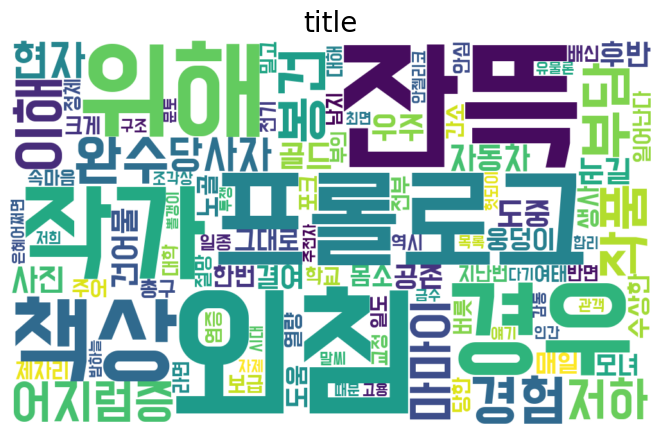

<Figure size 640x480 with 0 Axes>

In [27]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 주요 단어를 문자열로 변환 (예: '단어1, 단어2, 단어3')
word_string = ", ".join(topics_df['주요 단어'].tolist())

# 워드클라우드 생성
wordcloud = WordCloud(
    font_path= font,  # 한글 폰트 경로
    width=1000,
    height=600,
    background_color='white',
    colormap='viridis',  # 색상 맵 설정
    max_words=200,  # 최대 단어 수
    random_state=42  # 랜덤 상태 설정
).generate(word_string)

# 워드클라우드 시각화
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # 축 제거
plt.title('title', fontsize=20)
plt.show()